# Labjournaal BM
## General
Template for labjournaal. See https://jupyter-notebook.readthedocs.io/en/stable/examples/Notebook/Working%20With%20Markdown%20Cells.html for options to use markdown.

**Name:**  
**Title of the experiment:**  
**Starting date:**  
**Expected enddate:**  
**Partner:**  
**Goal of the experiment:**  
**Research question:**  
**Expectations or Hypothesis:**  
**Desired accuracy:**  




In [2]:
#import necessary libraries
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit 

# Preparation
 


**Assignments:**  

**Method:**  
**Theory:**  
**Independent variable:**  
**Dependent variable:**  
**Controlled variablen:**  
**Measurement instruments \& Settings:**  
**Procedure:**  
**Setup(drawing or picture):**  
**Notes:**  
**About accuracy:**  


# Execution

In [3]:
# Inladen data
with open("/Users/pieterjellebiesheuvel/Documents/TN/1ejaar/Q2/Bepaling constante van Boltzmann/metingen.csv") as f:
    regels_metingen = f.read().replace(",", ".").splitlines()
gemeten_U_bron, gemeten_U_R1 = np.loadtxt(regels_metingen, delimiter=";", skiprows=1, usecols=(1, 2), unpack=True)

weerstanden_bestands_naam="/Users/pieterjellebiesheuvel/Documents/TN/1ejaar/Q2/Bepaling constante van Boltzmann/weerstandBM.csv"
with open(weerstanden_bestands_naam) as f:
    regels_weerstanden = f.read().replace(",", ".").splitlines()

np_regels_weerstanden = np.loadtxt(regels_weerstanden, delimiter=";", skiprows=2)
R_een=np_regels_weerstanden[6,2] #10k ohm
R_twee=np_regels_weerstanden[4,2] #1000 ohm
R_drie=np_regels_weerstanden[2,2] #330 ohm

**Observations:**  
**Notes:**  

# Processing
**Description of processing of raw data into scientific evidence:**


In [4]:
#Functies:
def I_van_R_een(U_R_1):  #en daarbij van diode
    return U_R_1/R_een
def U_van_Diode(U_bron,U_R_1):
    return (U_bron*R_drie)/(R_twee+R_drie) - U_R_1
I_D = I_van_R_een(gemeten_U_R1)
U_D = U_van_Diode(gemeten_U_bron,gemeten_U_R1)

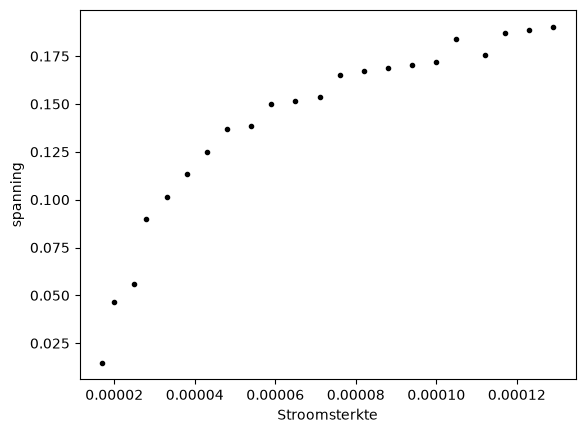

In [5]:
#Eerste plot:
plt.figure()
plt.plot(I_D[U_D>0],U_D[U_D>0],".k")
plt.xlabel("Stroomsterkte")
plt.ylabel("spanning")
plt.show()

In [6]:
#Data processing and analysis:
def onzekerheid_driehalf_voltage(meetpunt: int):
    return 0.007 * meetpunt + 0.01
def onzekerheid_vijfhalf_voltage(meetpunt: int):
    return meetpunt *0.00015 
def onzekerheid_vijfhalf_weerstand(R):
    return 0.0002 * R
uncer_U_Bron=onzekerheid_vijfhalf_voltage(gemeten_U_bron)
uncer_U_R1=onzekerheid_driehalf_voltage(gemeten_U_R1)


uncer_R1=onzekerheid_vijfhalf_weerstand(R_een)
uncer_R2=onzekerheid_vijfhalf_weerstand(R_twee)
uncer_R3=onzekerheid_vijfhalf_weerstand(R_drie)

uncer_U_D = np.sqrt(uncer_U_Bron**2 + uncer_U_R1**2)
uncer_I_D = I_D * np.sqrt((uncer_U_R1 / gemeten_U_R1)**2 + (uncer_R1 / R_een)**2)

**Describing the pattern in the processed data:**  


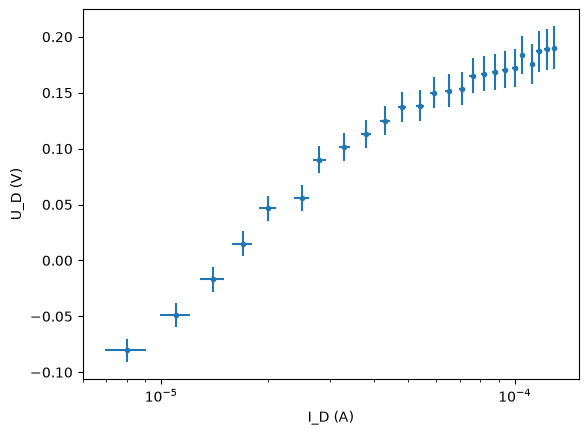

In [21]:
#Calculations of e.a. measurement uncertainties, and providing final answers.
plt.figure()
plt.errorbar(I_D, U_D, xerr=uncer_I_D, yerr=uncer_U_D, fmt=".")
plt.xscale("log")
plt.ylabel("U_D (V)")
plt.xlabel("I_D (A)")
plt.show()

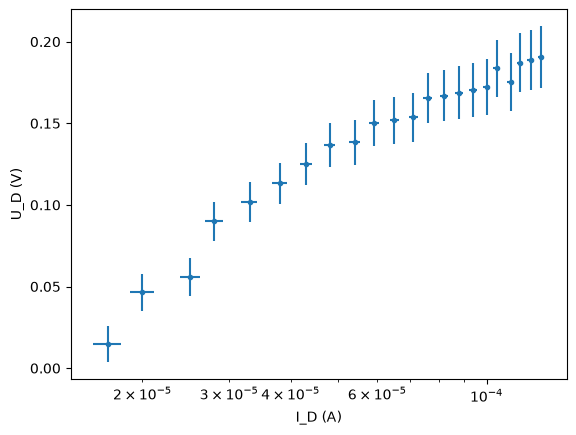

In [20]:
#Er zijn punten waar de spanning kleiner is dan 0. Dit is niet in overeenstemming met het model. Daarom filteren we ze eruit
selectie = U_D > 0
plt.figure()
plt.errorbar( I_D[selectie], U_D[selectie], xerr=uncer_I_D[selectie], yerr=uncer_U_D[selectie], fmt=".")
plt.xscale("log")
plt.ylabel("U_D (V)")
plt.xlabel("I_D (A)")
plt.show()

In [57]:
def I_diode(VD,INul,Kb):
    n=2
    T=293
    q=-1.602*(10**-19)
    return INul * (((np.e)**(-q*VD/(n*Kb*T)))-1)
popt,pcov = curve_fit(I_diode, U_D[selectie], I_D[selectie], p0=[10**-5, 10**-23])
print(f"Kb: {np.array(popt[1])} ± {np.sqrt(np.diag(pcov)[1])}")

Kb: 1.9741509857280604e-23 ± 1.8836506939521952e-24


**Notes:**  

# Discussion



# Conclusion

# Additional notes, remarks, explanations, thoughts etc